In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import date
import requests


df = pd.read_csv("../data/validated/train_validated_2023-05-26_2025-12-31.csv")
df["tid"] = pd.to_datetime(df["tid"], utc=True).dt.tz_convert("Europe/Stockholm")
df = df.set_index("tid")

print(df.index.min(), "–", df.index.max())
df.head()

2023-05-26 00:00:00+02:00 – 2025-12-31 23:00:00+01:00


,pm25,Lufttemperatur,Vindriktning,Vindhastighet,Relativ luftfuktighet,Nederbördsmängd
tid,,,,,,
2023-05-26 00:00:00+02:00,NaN,11.2,318.0,4.5,74.0,0.0
2023-05-26 01:00:00+02:00,NaN,10.4,308.0,4.1,76.0,0.0
2023-05-26 02:00:00+02:00,13.042,9.8,308.0,4.1,78.0,0.0
2023-05-26 03:00:00+02:00,13.116,9.5,304.0,4.6,81.0,0.0
2023-05-26 04:00:00+02:00,13.728,9.3,302.0,4.0,83.0,0.0


In [2]:
VECKODAGAR = ["måndag", "tisdag", "onsdag", "torsdag", "fredag", "lördag", "söndag"]

def rita_vecka(startdatum):
    """Ritar PM2.5 vid Dalaplan för sju dygn från startdatum."""
    start = pd.Timestamp(startdatum, tz="Europe/Stockholm")
    slut = start + pd.Timedelta(days=7)
    vecka = df[(df.index >= start) & (df.index < slut)]

    if start.weekday() != 0:
        print(f"Obs: startdatum är en {VECKODAGAR[start.weekday()]}, inte en måndag.")
    print(f"Saknade timmar för PM2.5 den här veckan: {vecka['pm25'].isna().sum()}")

    fig, ax = plt.subplots(figsize=(14, 4))

    ax.plot(vecka.index, vecka["pm25"], color="tab:purple")
    ax.axhline(15, color="grey", linestyle="--", linewidth=1, label="WHO dygnsriktvärde (15)")
    ax.set_ylabel("PM2.5 (µg/m³)")
    ax.legend(loc="upper right")

    # En vertikal linje vid varje midnatt, och veckodagen som etikett
    midnatter = [start + pd.Timedelta(days=d) for d in range(8)]
    for m in midnatter:
        ax.axvline(m, color="grey", linewidth=0.5, alpha=0.6)
    ax.grid(alpha=0.3)

    ax.set_xticks(midnatter[:-1])
    ax.set_xticklabels([f"{VECKODAGAR[m.weekday()]}\n{m:%d/%m}" for m in midnatter[:-1]], ha="left")
    ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 12, 18], tz="Europe/Stockholm"))
    ax.set_xlim(start, slut)

    ax.set_title(f"PM2.5 vid Dalaplan, vecka från {VECKODAGAR[start.weekday()]} {start:%Y-%m-%d}")
    plt.tight_layout()
    plt.show()

Saknade timmar för PM2.5 den här veckan: 0


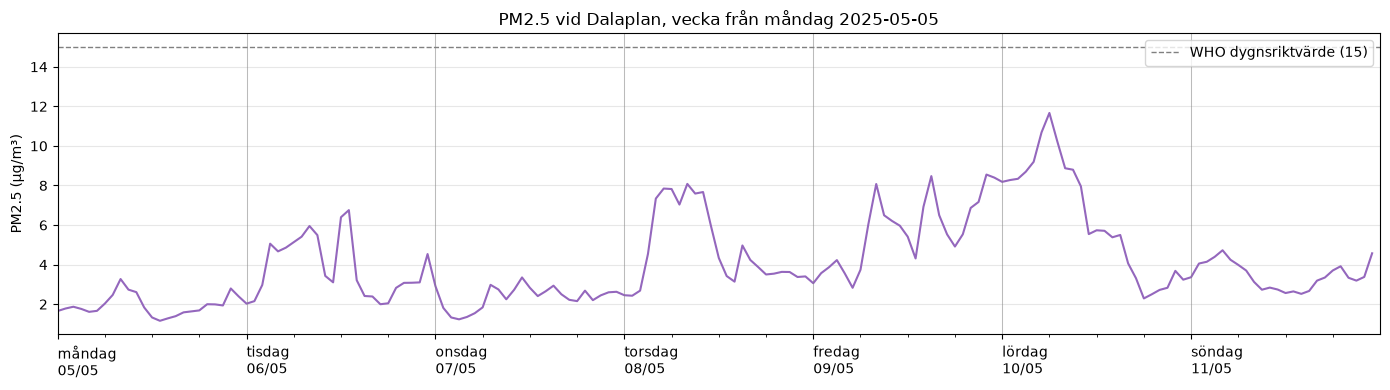

In [3]:
rita_vecka(date(2025, 5, 5))

In [4]:
ar = df.loc["2025"].copy()
ar["veckodag"] = ar.index.dayofweek          # måndag = 0, söndag = 6
ar["timme"] = ar.index.hour                  # i svensk tid
ar["veckotimme"] = ar["veckodag"] * 24 + ar["timme"]   # 0–167, måndag 00 till söndag 23

print(f"{len(ar)} timmar, varav {ar['pm25'].isna().sum()} utan PM2.5")

8760 timmar, varav 28 utan PM2.5


## Typisk vecka, måndag till söndag

Linjen visar medianen för varje timme i veckan, och det skuggade fältet var hälften av alla värden ligger (25–75 %). Jag använder median i stället för medelvärde, eftersom några få timmar med mycket höga halter annars drar upp kurvan.

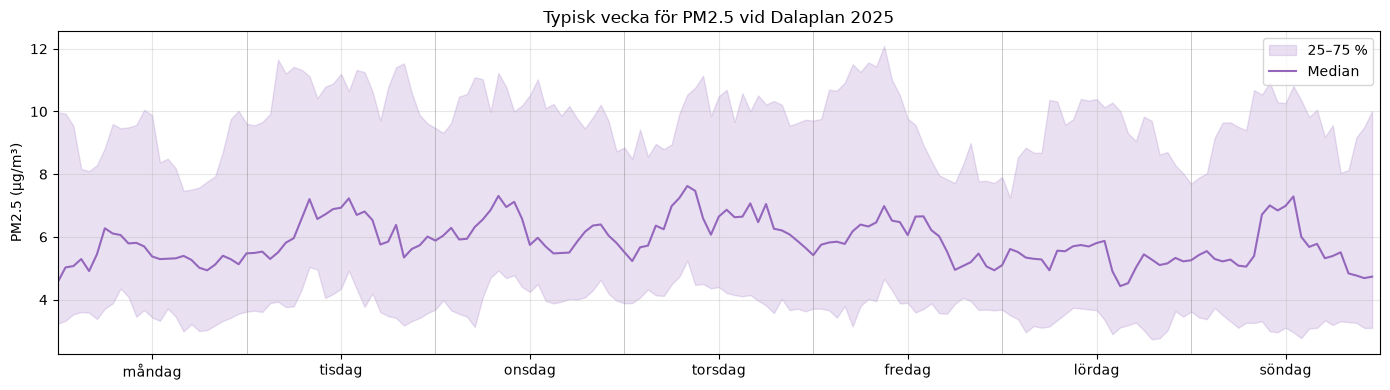

In [5]:
profil = ar.groupby("veckotimme")["pm25"].agg(
    median="median",
    q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75),
)

fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(profil.index, profil["q25"], profil["q75"], color="tab:purple", alpha=0.2, label="25–75 %")
ax.plot(profil.index, profil["median"], color="tab:purple", label="Median")

for d in range(8):
    ax.axvline(d * 24, color="grey", linewidth=0.5, alpha=0.6)
ax.set_xticks([d * 24 + 12 for d in range(7)])
ax.set_xticklabels(VECKODAGAR)
ax.set_xlim(0, 168)
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Typisk vecka för PM2.5 vid Dalaplan 2025")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Vardag mot helg, över ett dygn

Det här är ofta det tydligaste sättet att se om trafiken påverkar: två kurvor över dygnets 24 timmar, en för vardagar och en för helger.

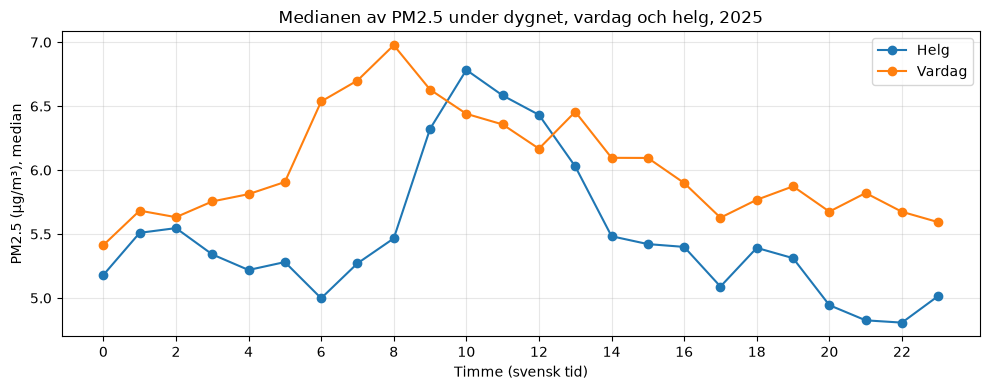

In [8]:
ar["dagtyp"] = ar["veckodag"].map(lambda d: "Helg" if d >= 5 else "Vardag")
dygn = ar.groupby(["daltyp", "timme"])["pm25"].median().unstack(0)

fig, ax = plt.subplots(figsize=(10, 4))
dygn.plot(ax=ax, marker="o")
ax.legend(title=None)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Timme (svensk tid)")
ax.set_ylabel("PM2.5 (µg/m³), median")
ax.set_title("Medianen av PM2.5 under dygnet, vardag och helg, 2025")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Median av PM2.5 per vecka under året (all träningsdata)

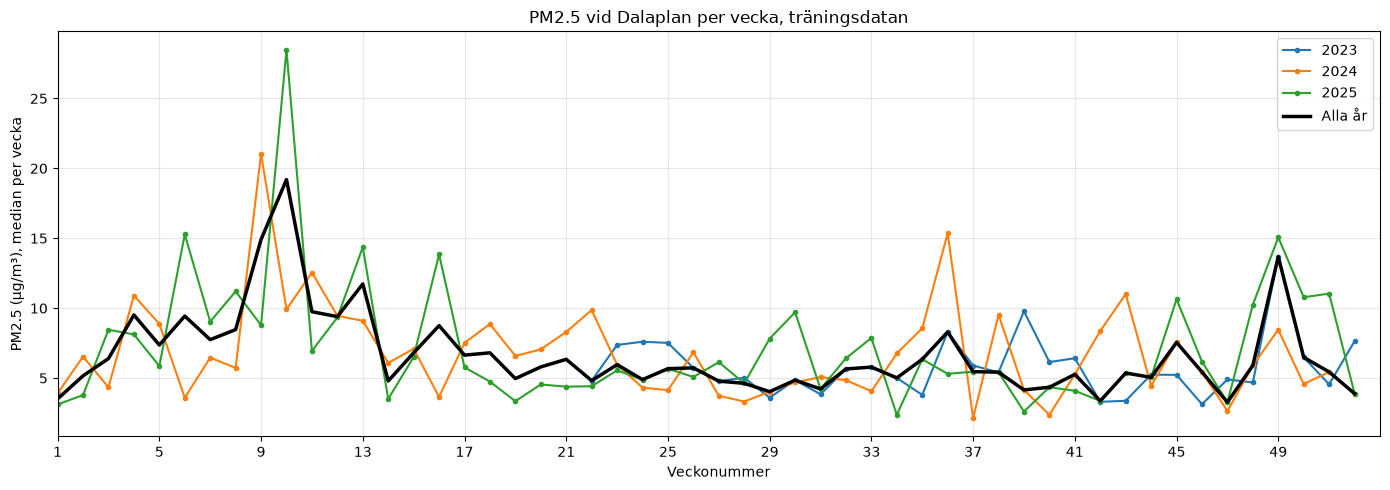

In [9]:
vecka_df = df.copy()
iso = vecka_df.index.isocalendar()
vecka_df["ar"] = iso.year.values
vecka_df["vecka"] = iso.week.values

# Median och antal mätningar per vecka och år
per_vecka = (
    vecka_df.groupby(["ar", "vecka"])["pm25"]
    .agg(median="median", antal="count")
    .reset_index()
)

# Ta bara med veckor med minst 4 dygns mätningar, så att halva veckor inte ger missvisande värden
per_vecka = per_vecka[per_vecka["antal"] >= 4 * 24]

fig, ax = plt.subplots(figsize=(14, 5))
for ar, grupp in per_vecka.groupby("ar"):
    ax.plot(grupp["vecka"], grupp["median"], marker="o", markersize=3, label=str(ar))

# Median över alla år för varje veckonummer
alla_ar = per_vecka.groupby("vecka")["median"].median()
ax.plot(alla_ar.index, alla_ar.values, color="black", linewidth=2.5, label="Alla år")

ax.set_xticks(range(1, 53, 4))
ax.set_xlim(1, 53)
ax.set_xlabel("Veckonummer")
ax.set_ylabel("PM2.5 (µg/m³), median per vecka")
ax.set_title("PM2.5 vid Dalaplan per vecka, träningsdatan")
ax.legend(title=None)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Kollar även Rådhuset

In [11]:


LUFT_API = "https://datavardluft.smhi.se/52North/api"
info = requests.get(f"{LUFT_API}/timeseries/6161", timeout=60).json()

print(info["label"])
print("Första värde:", pd.to_datetime(info["firstValue"]["timestamp"], unit="ms", utc=True).tz_convert("Europe/Stockholm"))
print("Senaste värde:", pd.to_datetime(info["lastValue"]["timestamp"], unit="ms", utc=True).tz_convert("Europe/Stockholm"))

PM2.5 SPP-SE0001A_06001_100_103, Malmö Rådhuset, SPP-SE0001A_06001_100_103
Första värde: 2022-01-01 00:00:00+01:00
Senaste värde: 2026-10-13 10:00:00+02:00


In [12]:
import sys
from pathlib import Path

projekt_rot = Path.cwd().parent
sys.path.insert(0, str(projekt_rot))
from src.extracting_data import hamta_pm25

RADHUSET_FIL = projekt_rot / "data" / "raw" / "eda_radhuset_pm25_2023-05-26_2025-12-31.csv"

if RADHUSET_FIL.is_file():
    radhuset = pd.read_csv(RADHUSET_FIL)
    radhuset["tid"] = pd.to_datetime(radhuset["tid"], utc=True).dt.tz_convert("Europe/Stockholm")
    radhuset = radhuset.set_index("tid")
else:
    radhuset = hamta_pm25("2023-05-26", "2025-12-31", 6161, LUFT_API)
    radhuset.to_csv(RADHUSET_FIL)

# Samma grundläggande kontroller som valideringen gör
radhuset = radhuset[~radhuset.index.duplicated()].sort_index()
radhuset.loc[radhuset["pm25"] < 0, "pm25"] = float("nan")

print(f"{len(radhuset)} timmar, {radhuset['pm25'].isna().sum()} saknade värden")

Hämtar 2023-05...
Hämtar 2023-06...
Hämtar 2023-07...
Hämtar 2023-08...
Hämtar 2023-09...
Hämtar 2023-10...
Hämtar 2023-11...
Hämtar 2023-12...
Hämtar 2024-01...
Hämtar 2024-02...
Hämtar 2024-03...
Hämtar 2024-04...
Hämtar 2024-05...
Hämtar 2024-06...
Hämtar 2024-07...
Hämtar 2024-08...
Hämtar 2024-09...
Hämtar 2024-10...
Hämtar 2024-11...
Hämtar 2024-12...
Hämtar 2025-01...
Hämtar 2025-02...
Hämtar 2025-03...
Hämtar 2025-04...
Hämtar 2025-05...
Hämtar 2025-06...
Hämtar 2025-07...
Hämtar 2025-08...
Hämtar 2025-09...
Hämtar 2025-10...
Hämtar 2025-11...
Hämtar 2025-12...
22826 timmar, 57 saknade värden


In [13]:
stationer = {
    "Dalaplan (gaturum)": df["pm25"],
    "Rådhuset (urban bakgrund)": radhuset["pm25"],
}

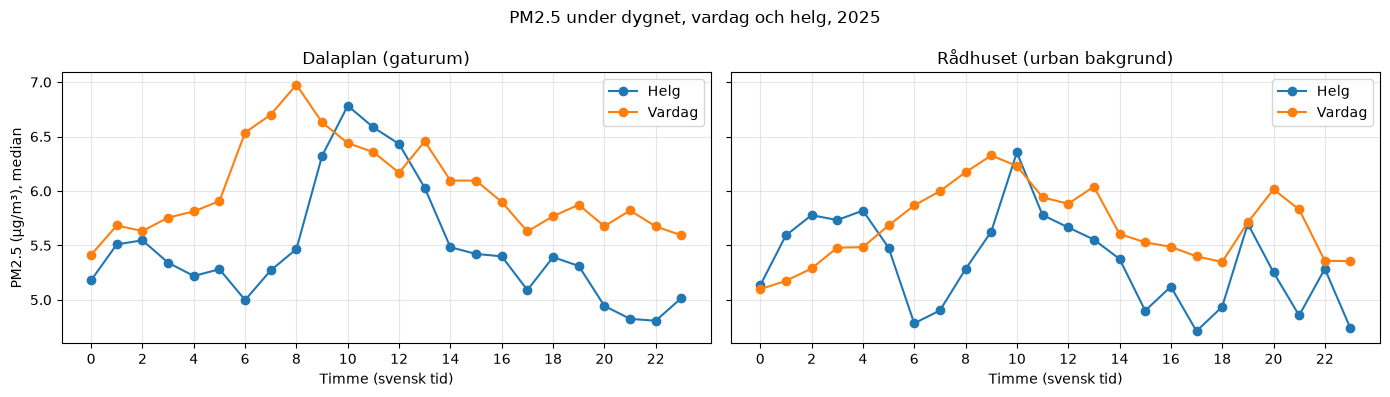

In [14]:
def vardag_helg_profil(serie, ar="2025"):
    data = serie.loc[ar].to_frame("pm25")
    data["timme"] = data.index.hour
    data["dagtyp"] = data.index.dayofweek.map(lambda d: "Helg" if d >= 5 else "Vardag")
    return data.groupby(["dagtyp", "timme"])["pm25"].median().unstack(0)

fig, axlar = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (namn, serie) in zip(axlar, stationer.items()):
    vardag_helg_profil(serie).plot(ax=ax, marker="o")
    ax.set_title(namn)
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel("Timme (svensk tid)")
    ax.legend(title=None)
    ax.grid(alpha=0.3)
axlar[0].set_ylabel("PM2.5 (µg/m³), median")
fig.suptitle("PM2.5 under dygnet, vardag och helg, 2025")
plt.tight_layout()
plt.show()

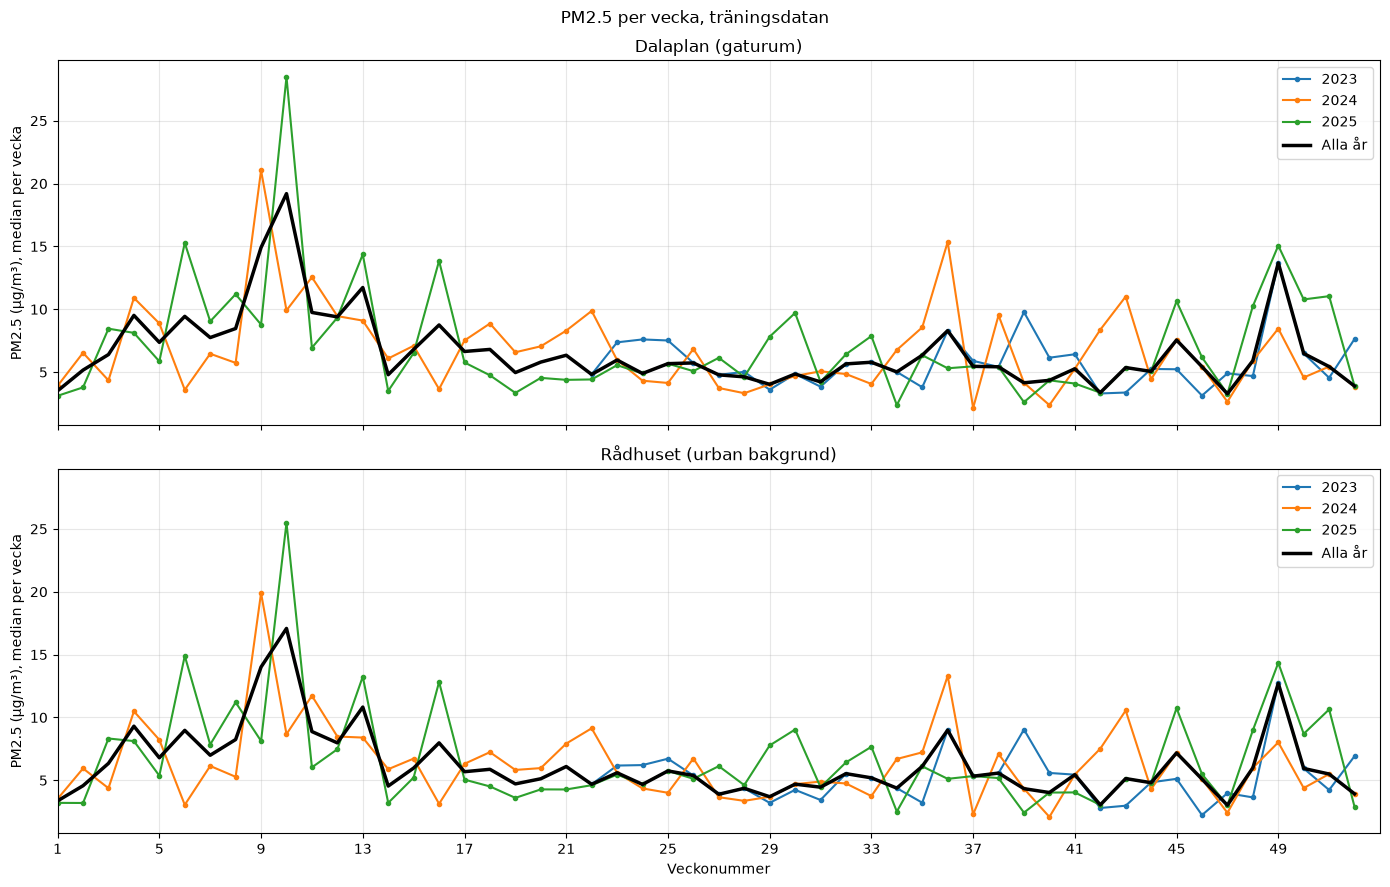

In [15]:
def median_per_vecka(serie, min_timmar=4 * 24):
    data = serie.to_frame("pm25")
    iso = data.index.isocalendar()
    data["ar"] = iso.year.values
    data["vecka"] = iso.week.values
    per_vecka = data.groupby(["ar", "vecka"])["pm25"].agg(median="median", antal="count").reset_index()
    return per_vecka[per_vecka["antal"] >= min_timmar]

fig, axlar = plt.subplots(2, 1, figsize=(14, 9), sharex=True, sharey=True)
for ax, (namn, serie) in zip(axlar, stationer.items()):
    per_vecka = median_per_vecka(serie)
    for ar, grupp in per_vecka.groupby("ar"):
        ax.plot(grupp["vecka"], grupp["median"], marker="o", markersize=3, label=str(ar))
    alla_ar = per_vecka.groupby("vecka")["median"].median()
    ax.plot(alla_ar.index, alla_ar.values, color="black", linewidth=2.5, label="Alla år")
    ax.set_title(namn)
    ax.set_ylabel("PM2.5 (µg/m³), median per vecka")
    ax.legend(title=None)
    ax.grid(alpha=0.3)

axlar[1].set_xticks(range(1, 53, 4))
axlar[1].set_xlim(1, 53)
axlar[1].set_xlabel("Veckonummer")
fig.suptitle("PM2.5 per vecka, träningsdatan")
plt.tight_layout()
plt.show()